# Topic analysis of state AI legislation

**Question.** Which policy themes recur across state AI bills, how do they differ across states and over time, and do bills in different domains share the same safeguards?

**Approach.** TF-IDF and NMF with eight topics, fit on the NCSL summary of each bill. States, dates and outcomes are not model inputs; they are used afterwards to describe the topics.

**Run.** `python -m pip install -r requirements.txt`, then `python src/prepare.py`, then run all cells. Tables and figures are saved to `outputs/topic_analysis/`.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from threadpoolctl import threadpool_limits

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(root))  # so the notebook can import src/topic_analysis.py

from src.topic_analysis import (
    TEXT, LEGAL_STOPWORDS, load_common, dominant_topics, check_topic_identity, fit_model,
    leading_word_chart, heatmap, group_share_tables, run_experiments, k_selection, recommend_k,
    k_selection_chart, new_topics_versus, case_evidence, distinct_solutions, pair_stability,
    outcome_by_topic, outcome_chart, bill_families,
)

OUT = root / "outputs/topic_analysis"
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", None)

## 1. Data

The input is the shared table from `src/prepare.py`. Four bills whose full text repeats a later record were already removed there.

In [2]:
work, audit = load_common(root)  # also checks every value against the raw file

words = work[TEXT].str.split().str.len()
print(f"{len(work):,} bills from {work.Jurisdiction.nunique()} jurisdictions")
print(f"Summary length: median {words.median():.0f} words")

work[["Jurisdiction", "Bill_Number", TEXT]].head(3)

2,567 bills from 51 jurisdictions
Summary length: median 32 words


,Jurisdiction,Bill_Number,NCSL_Summary_clean
0,Alabama,H 208,"Relates to secretary of Information Technology, duties cybertechnology technology quality assurance for state agencies further provided."
1,Alabama,H 365,"Relates to state Science, Technology, Engineering, and Mathematics Council created in the Department of Workforce, membership and duties provided."
2,Alabama,H 515,Relates to AI; regulate use in health coverage decisions.


## 2. Topic model

**Why summaries rather than full text.** Cleaned full texts have a median of about 1,000 words (roughly 400 to 3,200 between the 10th and 90th percentiles), so long bills and legal boilerplate would dominate the topics. For 37% of records the stored version date differs from the introduction date, so the stored text may be an amended version. NCSL summaries are short and written in one consistent format. Full text is still used to check the eight cases in section 5.

**Settings.** English stopwords, unigrams and bigrams, `min_df=3`, `max_df=0.85`; NMF with eight topics, NNDSVDa initialization, seed 42.

**Four extra stopwords.** About a quarter of summaries open with the formula "Relates to ...", and the plain model spends a whole topic on it. Dropping `relates`, `provides`, `act` and `section` removes it. This refined model is used throughout; the plain one is compared in section 4.

In [3]:
stop_words = sorted(set(ENGLISH_STOP_WORDS) | LEGAL_STOPWORDS.keys())
vectorizer = TfidfVectorizer(stop_words=stop_words, ngram_range=(1, 2), min_df=3, max_df=0.85)
X = vectorizer.fit_transform(work[TEXT])

nmf = NMF(n_components=8, init="nndsvda", random_state=42, max_iter=500)
with threadpool_limits(limits=2):
    W = nmf.fit_transform(X)  # one row of topic weights per bill

print("Bills x terms:", X.shape)

Bills x terms: (2567, 6168)


In [4]:
# Topic names were written after reading each topic's top words and its five highest-weight summaries.
labels = json.loads((root / "notebooks/topic_labels.json").read_text(encoding="utf-8"))
names = [topic["name"] for topic in labels]

# Stop if any topic's top words differ from the ones the names were written for.
check_topic_identity(dict(model=nmf, vectorizer=vectorizer), labels)

terms = vectorizer.get_feature_names_out()
topics = dominant_topics(W)  # strongest topic per bill; -1 if the summary has no terms left

pd.DataFrame({
    "topic": range(8),
    "name": names,
    "bills": [(topics == t).sum() for t in range(8)],
    "top words": [", ".join(terms[np.argsort(-row)[:8]]) for row in nmf.components_],
})

,topic,name,bills,top words
0,0,Generic artificial-intelligence wording (weak),319,"artificial intelligence, intelligence, artificial, use artificial, use, intelligence systems, creates, establishes"
1,1,AI and generative-AI wording (weak),352,"ai, use ai, use, generative, generative ai, ai systems, requires, systems"
2,2,Synthetic media in political communications,213,"media, synthetic, synthetic media, election, deceptive, political, use synthetic, communications"
3,3,"State administration, education and study bodies (broad)",515,"state, task, task force, force, education, department, requires, technology"
4,4,Automated decisions across application domains,166,"decision, automated, employment, automated decision, use automated, systems, making, tools"
5,5,Sexual exploitation and intimate imagery,412,"sexual, child, person, image, images, material, intimate, minor"
6,6,Health services and coverage,232,"health, care, health care, insurance, services, mental, mental health, health insurance"
7,7,Algorithmic pricing and consumer restrictions,357,"prohibits, algorithmic, consumer, pricing, residential, price, certain, prohibits use"


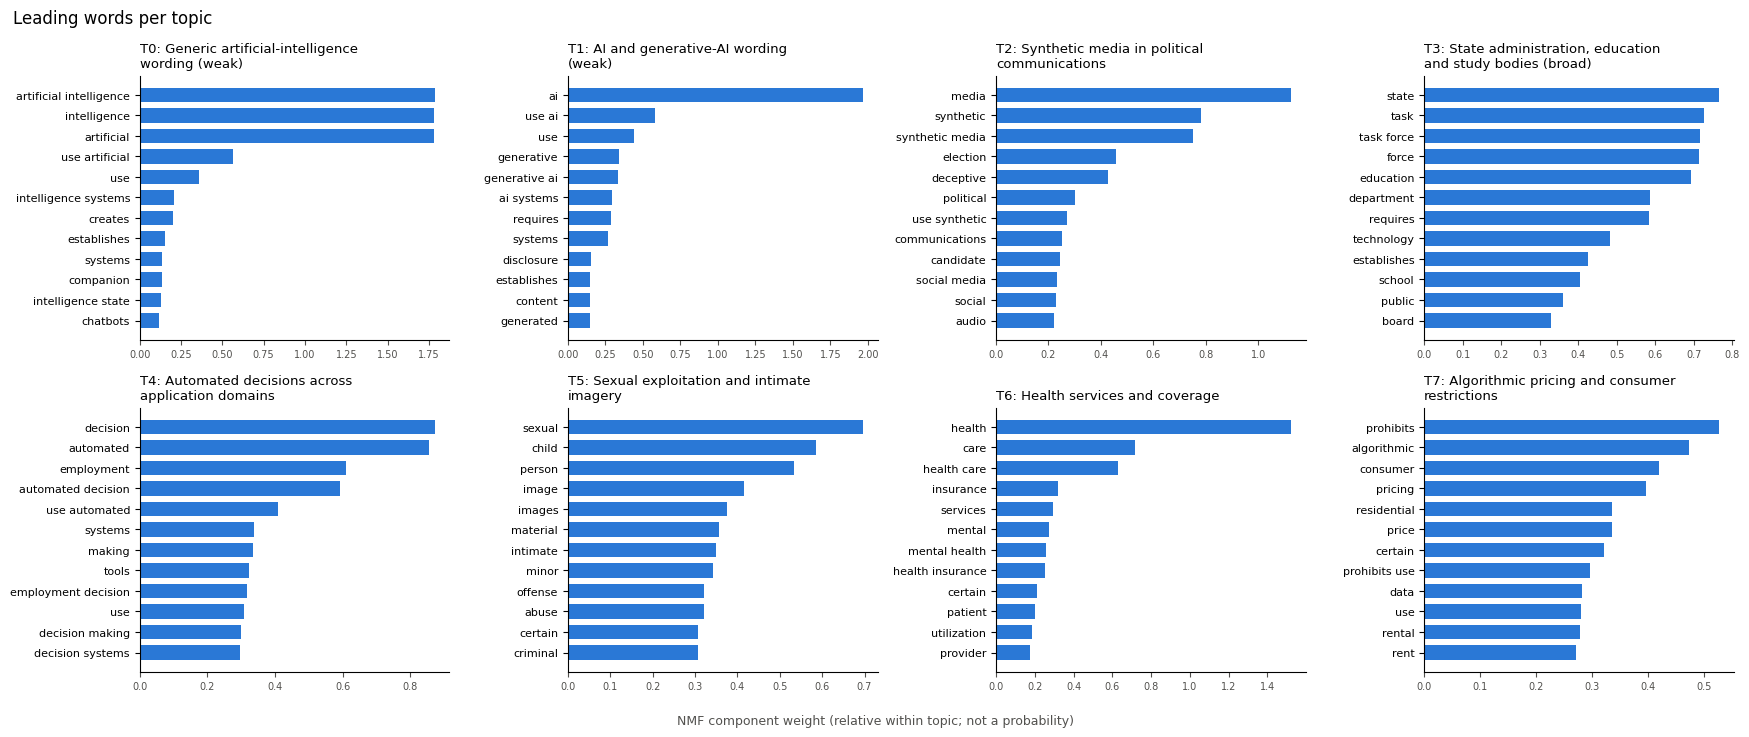

In [5]:
leading_word_chart(nmf, vectorizer, names, "Leading words per topic", OUT / "refined_leading_words.png")
plt.show()

T0 and T1 collect generic AI wording rather than a policy area. One summary (Illinois HR 142) has no terms left after filtering and stays unassigned.

## 3. Where the topics appear

Each bill's topic weights are turned into shares that sum to 1, then averaged by state and by introduction year. Shares describe the bills in this dataset, not how much a state cares about a policy.

In [6]:
group_tables = group_share_tables(work, W, OUT, "refined")  # mean shares; also saved as CSV
state_means, state_counts = group_tables["state"]
year_means, year_counts = group_tables["cohort"]

topic_columns = {t: f"T{t}: {name}" for t, name in enumerate(names)}

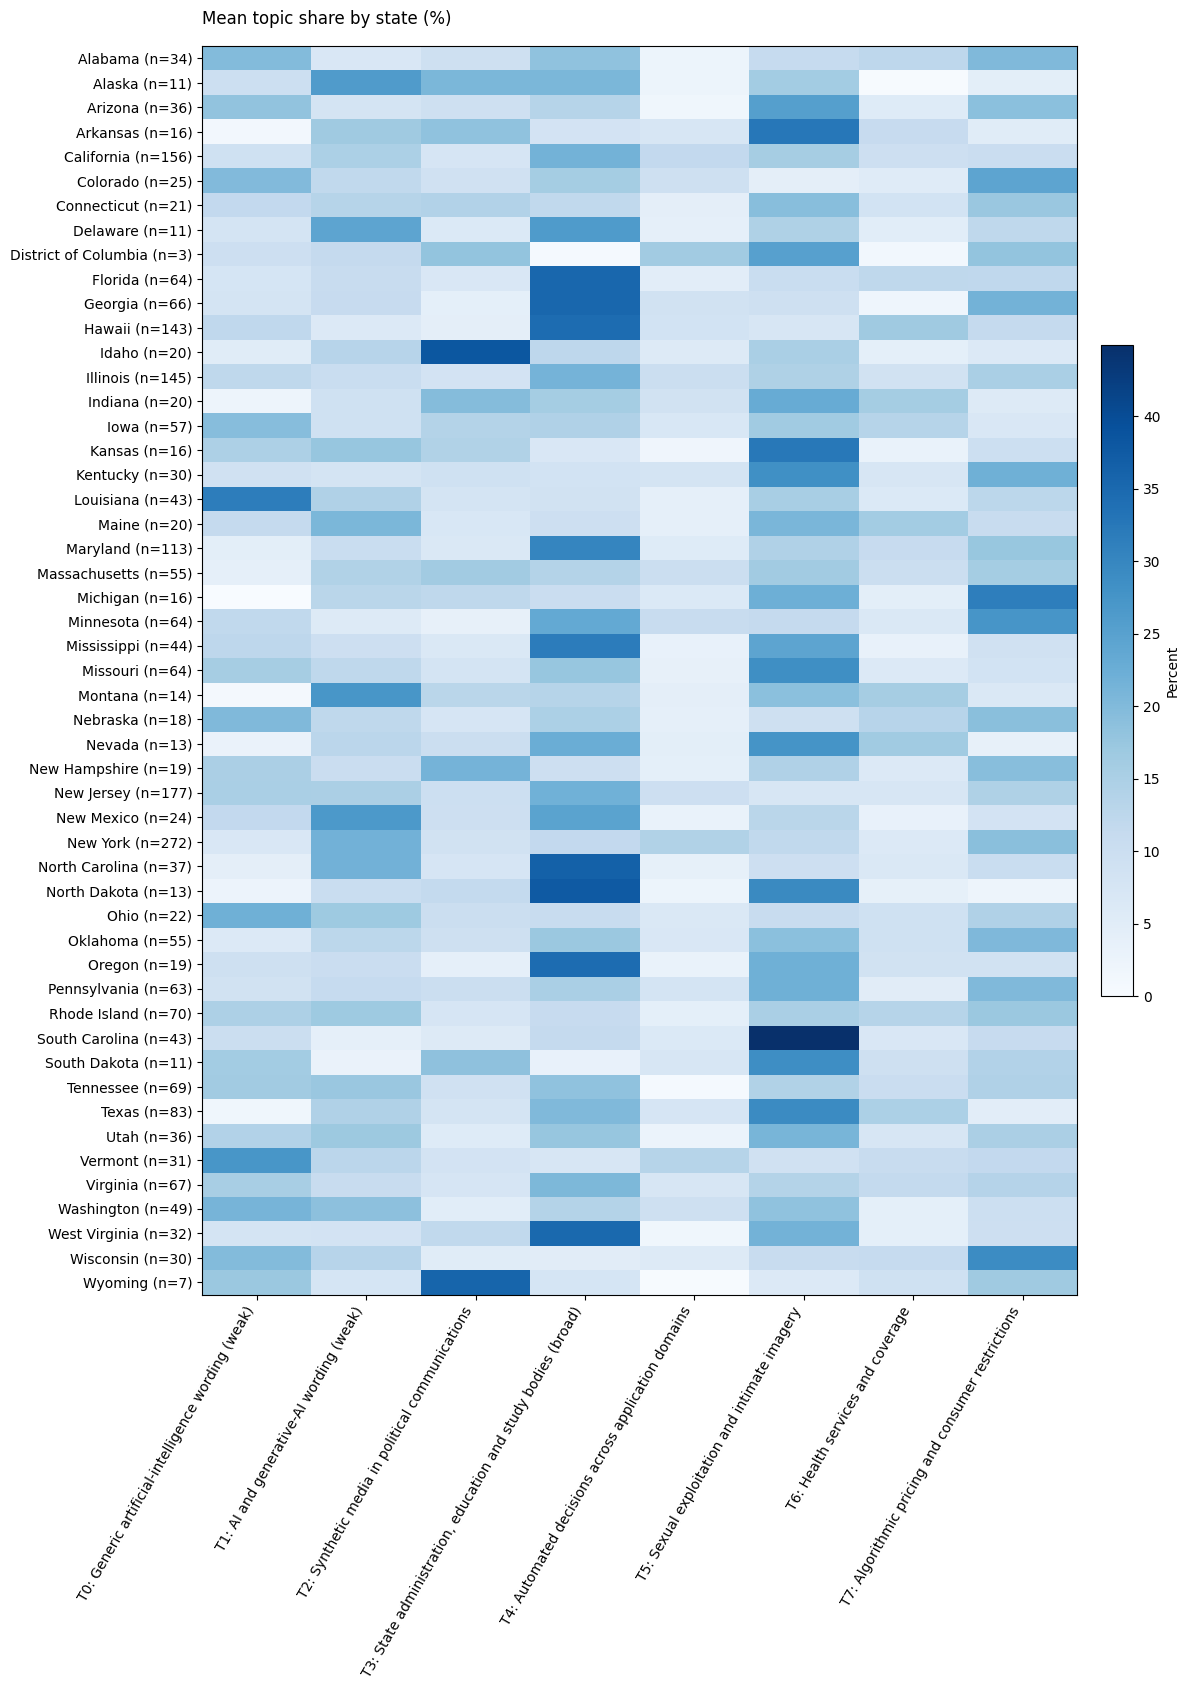

In [7]:
state_rows = {state: f"{state} (n={n})" for state, n in state_counts.records.items()}

heatmap(state_means.rename(index=state_rows, columns=topic_columns),
        "Mean topic share by state (%)", OUT / "refined_state_mean_topic_shares.png",
        percent=True, size=(12, 17), vmax=100 * state_means.to_numpy().max())
plt.show()

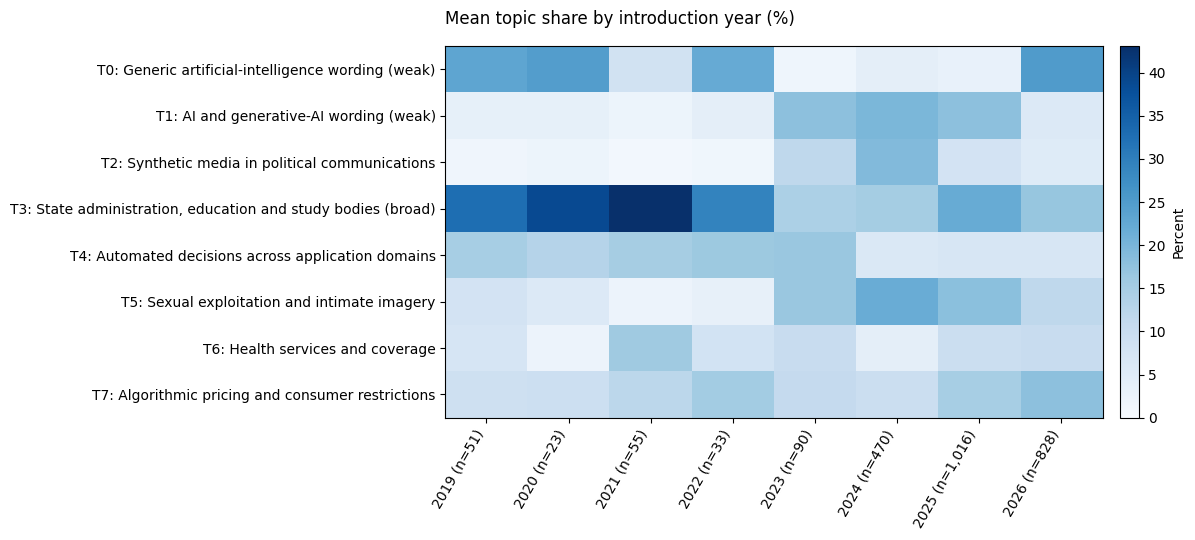

Latest introduction date: 2026-04-02 (2026 is a partial year)


In [8]:
year_means = year_means.loc[year_counts.records >= 5]  # 2018 has a single bill
year_columns = {year: f"{year} (n={n:,})" for year, n in year_counts.records.items()}

heatmap(year_means.T.rename(index=topic_columns, columns=year_columns),
        "Mean topic share by introduction year (%)", OUT / "refined_cohort_mean_topic_shares.png",
        percent=True, size=(12, 5.5), vmax=100 * year_means.to_numpy().max())
plt.show()

print("Latest introduction date:", work.introduction_date_iso.max(), "(2026 is a partial year)")

## 4. Model choice

**NMF versus LDA, and the four extra stopwords.** Each model is fit with eight topics and compared on coherence (NPMI of the top 12 words; higher is better), term diversity (share of distinct words across topics; higher is better) and overlap between topics (lower is better). The plain baseline is fit first because the other runs are compared with it.

In [9]:
baseline_vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=3, max_df=0.85)
baseline_X = baseline_vectorizer.fit_transform(work[TEXT])

baseline_nmf = NMF(n_components=8, init="nndsvda", random_state=42, max_iter=500)
with threadpool_limits(limits=2):
    baseline_W = baseline_nmf.fit_transform(baseline_X)

baseline = dict(vectorizer=baseline_vectorizer, X=baseline_X, model=baseline_nmf, W=baseline_W)

# Also fits LDA, the refined and geography variants, other topic counts and other seeds.
bundles, comparison, all_topics, all_reps = run_experiments(work, baseline, OUT)

main_runs = comparison.query("topics == 8 and seed == 42 and initialization != 'random'")
main_runs[["method", "variant", "document_npmi_top12", "top12_term_diversity", "mean_top12_jaccard"]].round(2)

,method,variant,document_npmi_top12,top12_term_diversity,mean_top12_jaccard
2,NMF,baseline,0.16,0.89,0.02
13,NMF,legal,0.21,0.90,0.03
14,NMF,geography,0.16,0.88,0.03
15,NMF,legal_geography,0.24,0.91,0.02
17,LDA,baseline,0.09,0.59,0.14


NMF topics are clearly more distinct than LDA topics: term diversity 0.89 vs 0.59 and overlap 0.02 vs 0.14 (baseline vocabulary for both). LDA diversity stays at or below 0.59 for every k tested, so NMF is the main method. Dropping the four formula words raises NMF coherence from 0.16 to 0.21.

**How many topics.** Each k from 5 to 12 is fit five times (NNDSVDa plus four random starts). Rule: among the counts within 0.01 of the best mean NPMI, take the one whose topics match best across starts.

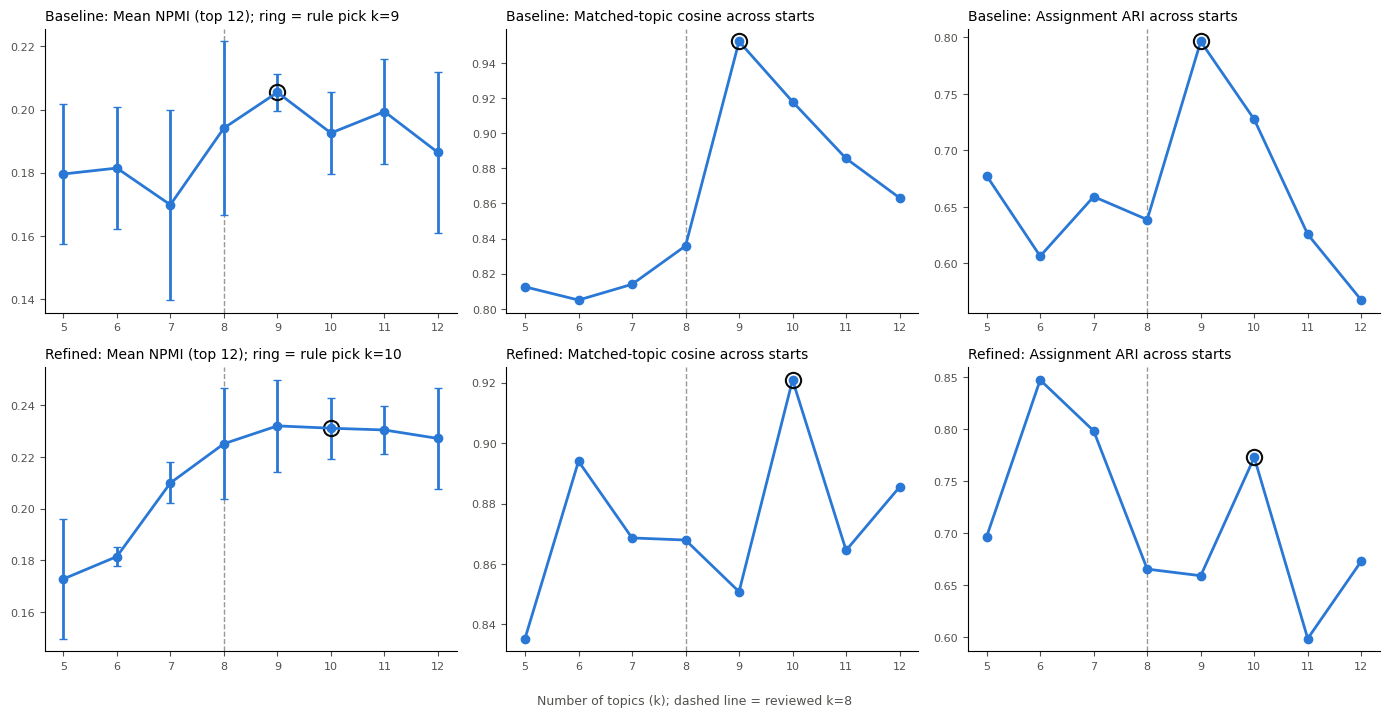

Rule picks: {'Baseline': 9, 'Refined': 10}


In [10]:
k_tables = {
    "Baseline": k_selection(work, OUT, "baseline"),
    "Refined": k_selection(work, OUT, "legal", prefix="refined"),
}
k_picks = {name: recommend_k(table) for name, table in k_tables.items()}

k_selection_chart(k_tables, 8, OUT / "k_selection.png")
plt.show()

print("Rule picks:", k_picks)

In [11]:
# Topics in the refined k=10 model that have no close match (cosine < 0.8) among the eight.
nmf_10, W_10, _, _ = fit_model(X, "NMF", k_picks["Refined"], 42, "nndsvda")
refined = dict(model=nmf, W=W, vectorizer=vectorizer)
new_topics_versus(refined, dict(model=nmf_10, W=W_10, vectorizer=vectorizer))

,topic_id,dominant_records,closest_reviewed_topic,closest_cosine,top_terms
0,3,61,3,0.581604,"task, task force, force, establishes, intelligence task, creates, establishes task, recommendations, force shall, membership"
1,9,19,3,0.008192,"commends, recognizes, dr, challenge, years, congratulates, continued success, wishes, wishes continued, dedicated"


**Decision: keep k=8.** The rule picks k=9 for the baseline and k=10 for the refined model, and the picks stay the same for tolerances from 0.005 to 0.03. The refined k=10 model keeps all eight topics and only adds two small ones: task forces (61 bills) and commendation resolutions (19). The eight topics were the ones read and labeled, so k=8 stays.

## 5. Eight cases: shared provisions across domains

Eight bills were picked by hand from the automated-decision and study-body topics to compare domains, states and obligations. They are examples, not a random sample. Every quote is taken from the stored `Bill_Text`, and the code checks that each one appears there exactly.

- **Safeguards around automated decisions.** IN H 1421 and NY A 9601 (employment) and SC S 443 (health coverage) ban relying only on automation and require human oversight. NY S 6471-A (housing) and NY S 8115-B (lending) share notice and assessment duties but not the same right to a human appeal.
- **Study bodies with reporting duties.** IL S 2481 (workforce), UT H 168 (education) and CO S 240 (criminal justice electronic discovery) set up study and reporting bodies in different domains. This is a shared way of organizing government, not a shared safeguard.
- **Same category, different approach.** IL S 2481 and IN H 1421 are both labeled `Effect on Labor/Employment`, but one creates a study body and the other puts duties on employers. The model separates them.

In [12]:
case_spec = json.loads((root / "notebooks/topic_case_review.json").read_text(encoding="utf-8"))
cases = case_evidence(work, case_spec["cases"], bundles, OUT)  # fails if a quote is not in Bill_Text

row_of = {source_row: i for i, source_row in enumerate(work.source_row)}
cases["topic"] = [topics[row_of[source_row]] for source_row in cases.source_row]

cases[["Jurisdiction", "Bill_Number", "application_domain", "topic", "concrete_requirements"]]

,Jurisdiction,Bill_Number,application_domain,topic,concrete_requirements
0,Indiana,H 1421,Employment,4,"No exclusive automated reliance; predeployment validation, annual independent bias testing with public results, experienced human corroboration, disclosure, and human dispute/appeal channels."
1,New York,A 9601,Employment,4,"Meaningful human evaluation before final/adverse decisions, override authority, notice of automated use and data types, and human review on an unsuccessful applicant's request."
2,South Carolina,S 443,Health coverage,4,No coverage action based solely on AI/tool results; professional supervision and meaningful review when automated tools inform modification or denial of authorization.
3,New York,S 6471,Housing applicant screening,4,"Annual disparate-impact analysis by an independent auditor; public analysis summary; notice about use, characteristics and data; denial reasons; at least 24-hour prior notice enabling an alternative selection process or accommodation request."
4,New York,S 8115,Lending,4,"At least annual impact assessments signed by responsible human reviewers, assessments before material changes, public final reports, notice, and a 30-day correction/appeal route for denials based on incorrect personal information."
5,Illinois,S 2481,Workforce and employment,3,"Assess emerging technologies and workforce effects, propose training and other policies, and submit a final report to the Governor and General Assembly."
6,Utah,H 168,Education,3,"Study and recommend education AI policies, privacy safeguards and implementation guidelines; coordinate with the AI policy office; meet at least quarterly and report annually to legislative education committees."
7,Colorado,S 240,Criminal justice electronic discovery,3,"Gather information on discovery services and access; study AI transcription availability; submit findings, recommendations and legislative proposals to budget and technology committees."


In [13]:
# Do the paired cases keep their relationship in every distinct NMF and LDA run?
# A "similar" pair should share a dominant topic; the one contrast pair should not.
distinct_bundles, collapsed_runs = distinct_solutions(bundles)  # runs with the same solution count once
pair_results = pair_stability(work, distinct_bundles, case_spec["pairs"], OUT)

pair_results["method"] = pair_results.run_id.str.split("_").str[0].str.upper()
pair_results["relationship_preserved"] = np.where(
    pair_results.expected_relation.eq("similar"), pair_results.same_dominant_topic, ~pair_results.same_dominant_topic)

pair_results.groupby("method").agg(
    distinct_runs=("run_id", "nunique"), checks=("run_id", "size"), relationship_held=("relationship_preserved", "sum"))

,distinct_runs,checks,relationship_held
method,,,
LDA,4,32,28
NMF,12,96,96


## 6. Exploratory checks (post hoc)

These two checks were added after the main review, so treat them as leads rather than tested results.

### Recorded outcomes by topic

- Only resolved bills count: Enacted and Adopted as passed, Failed and Vetoed as failed. Pending bills are left out.
- Resolutions and memorials (HR, SCR, HJM and similar) are removed.
- Each topic is compared with all others within the same introduction year and party control (Mantel–Haenszel odds ratio), so those two factors are held fixed.

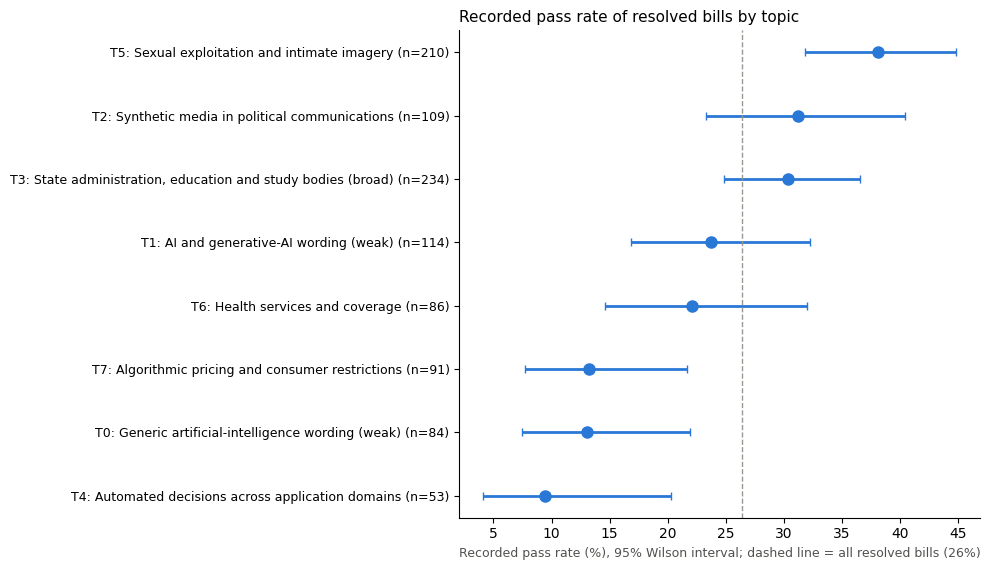

,name,resolved_bills,pass_rate,stratified_odds_ratio_vs_other_topics,cmh_p
0,Automated decisions across application domains,53,0.094,0.243,0.008
1,Generic artificial-intelligence wording (weak),84,0.131,0.589,0.194
2,Algorithmic pricing and consumer restrictions,91,0.132,0.438,0.011
3,Health services and coverage,86,0.221,0.687,0.213
4,AI and generative-AI wording (weak),114,0.237,0.695,0.159
5,"State administration, education and study bodies (broad)",234,0.303,1.352,0.108
6,Synthetic media in political communications,109,0.312,1.385,0.203
7,Sexual exploitation and intimate imagery,210,0.381,1.835,0.001


In [14]:
outcome_table, outcome_audit = outcome_by_topic(work, W, names, OUT, "refined")

outcome_chart(outcome_table, outcome_audit["overall_pass_rate"],
              "Recorded pass rate of resolved bills by topic", OUT / "refined_topic_outcomes.png")
plt.show()

outcome_table[["name", "resolved_bills", "pass_rate", "stratified_odds_ratio_vs_other_topics", "cmh_p"]].round(3)

### Multi-state bill families

Bills from different states whose full texts are near-identical (TF-IDF cosine ≥ 0.5) are linked. Groups that reach four or more states are listed. They usually point to a shared source such as model legislation.

In [15]:
families, family_thresholds, family_audit = bill_families(work, W, names, OUT)

print(f"{len(families)} families, {family_audit['bills_in_families']} bills")
print(f"Pass rate: family members {family_audit['family_pass_rate']:.0%} (n={family_audit['family_resolved_bills']}), "
      f"other bills {family_audit['other_pass_rate']:.0%} (n={family_audit['other_resolved_bills']})")

families[["states", "bills", "dominant_topic", "example_title", "resolved_bills", "passed"]]

11 families, 86 bills
Pass rate: family members 11% (n=28), other bills 27% (n=953)


,states,bills,dominant_topic,example_title,resolved_bills,passed
0,"Arizona, Hawaii, Iowa, Missouri, Nebraska, North Carolina, Oklahoma, Rhode Island, South Carolina",16,T2: Synthetic media in political communications,Electioneering Communications,10,0
1,"Illinois, Kentucky, New York, Ohio, Oklahoma, Rhode Island, South Carolina, Washington",11,T0: Generic artificial-intelligence wording (weak),Artificial Intelligence,1,0
2,"Illinois, Louisiana, Massachusetts, New York, Tennessee, Utah",8,T0: Generic artificial-intelligence wording (weak),Artificial Intelligence,2,1
3,"Colorado, Illinois, New York, Texas, Virginia",10,T7: Algorithmic pricing and consumer restrictions,Residential Landlord and Tenant Act,4,0
4,"California, Illinois, Oklahoma, Rhode Island, Washington",7,T4: Automated decisions across application domains,Automated Decision Tools,3,0
5,"Mississippi, New Jersey, Oklahoma, South Carolina, Tennessee",7,T5: Sexual exploitation and intimate imagery,ELVIS Act of 2025,4,1
6,"Kansas, Louisiana, Pennsylvania, Rhode Island, Vermont",6,"T3: State administration, education and study bodies (broad)",Clean Air Preservation Act,1,0
7,"Iowa, Nebraska, New York, Oklahoma, Tennessee",6,T7: Algorithmic pricing and consumer restrictions,Consumer Protection,0,0
8,"Colorado, New York, Oklahoma, Rhode Island",6,T7: Algorithmic pricing and consumer restrictions,Business Regulation Regarding Insurance Discrimination,3,1
9,"California, Iowa, Louisiana, New York",5,T4: Automated decisions across application domains,Employment: Automated Decision Systems,0,0


## 7. Key results

1. **Themes.** Six policy topics: synthetic media in political communications (T2), state administration, education and study bodies (T3), automated decisions (T4), sexual exploitation and intimate imagery (T5), health services and coverage (T6), and algorithmic pricing (T7). T0 and T1 are generic AI wording.
2. **States.** Among states with 40 or more bills, the largest shares are South Carolina for T5 (45%), Florida for T3 (35%), Minnesota for T7 (27%), Hawaii for T6 (17%), Massachusetts for T2 (16%) and New York for T4 (14%).
3. **Over time.** Study bodies (T3) and automated decisions (T4) peak in 2019–2023. Synthetic media (T2) and sexual imagery (T5) peak in 2024. Health (T6) and pricing (T7) peak in 2025–2026.
4. **Shared provisions.** The eight case relationships hold in all 96 checks across 12 distinct NMF solutions.
5. **Outcomes.** 26% of 981 resolved bills passed. Sexual exploitation (T5) passes most often (38%, odds ratio 1.84, the only topic below the Bonferroni threshold) and automated decisions (T4) least often (9%, odds ratio 0.24).
6. **Bill families.** 11 families covering 86 bills. Only 11% of family members passed, against 27% of other bills.

**Interpretation.**

- **From building capacity to targeting harms.** Early bills mostly created task forces, studies and rules for government use. States were still working out what AI meant for them before regulating anyone else.
- **2024 was the deepfake year.** An AI-generated robocall imitating a presidential candidate and viral fake intimate images of a celebrity made the harm concrete just before a national election. States answered quickly with disclosure rules for political ads and new offenses for synthetic intimate images. Tennessee's voice-likeness law became a template that other states copied.
- **Then the focus moved to money.** By 2025 attention turned to algorithmic rent-setting and other pricing software, after antitrust suits against rental-pricing tools drew national attention. AI therapy and companion chatbots followed as the next wave.
- **What passes is what is easy to agree on.** Bills that punish clear harms to identifiable victims pass far more often and draw more bipartisan sponsors. Bills that place duties on how businesses use automated decisions or set prices meet industry opposition and rarely pass; even Colorado's broad law was delayed after enactment.
- **Copying spreads ideas, not votes.** Near-identical bills appear in many states, yet in this snapshot the copied bills pass less often. Model legislation seems to move ideas faster than it builds local coalitions.

## 8. Limits

- Summaries can leave out actors, exceptions and obligations, and their fixed wording shapes the topics.
- The eight cases were chosen by hand, and the stored text may not match the current law.
- Bills are not independent: companion bills and repeated summaries remain.
- Section 6 was added after the main review and describes associations, not causes.